# Extension — Dynamic hedge ratio with a Kalman filter

Design pre-registered in `EXPERIMENTS.md` on 2026-10-10 at 14:05 CEST (**before** OOS access #1), with two clarifications at 16:10 (before any Kalman computation). Nothing was changed after seeing results.

- **Model:** `log P_INTC,t = α_t + β_t·log P_AMD,t + ε_t`, state (α_t, β_t) random walk; two-state filter in numpy; V = 0.001, W = δ/(1−δ)·I (Chan, 2013), **δ = 1e-4 main**, sensitivity δ ∈ {1e-5, 1e-4, 1e-3} (IS backtests #12–#14).
- **Initialization:** OLS on the first 252 IS days (mean and coefficient covariance); these days are excluded from evaluation. Only the **filtered** β_t (data up to t) is used.
- **Signal:** as Phase 2 (L = 60, ±2.0, exit at 0, `shift(1)`, 5 bp/leg, rf = 0); the z-score of day t applies β_t to the whole 60-day window (sample moments). P&L of day t+1 uses β_t; rebalancing costs from β changes are not counted (declared limitation).
- **OOS access #2** (logged at 16:12 before computing): δ = 1e-4 only, filter continuing from its IS state, starting flat on 2013-01-02.
- **Known property:** β_t is already updated with day t's prices, so the filter partly absorbs day t's deviation before the z-score is computed (not look-ahead; may dampen the signal).

In [1]:
import logging
from datetime import date

import pandas as pd
import plotly.graph_objects as go
from IPython.display import Image, display

from pairs.backtest import run_strategy
from pairs.config import SPLIT_DATE
from pairs.data import load_pair
from pairs.kalman import (
    KALMAN_DELTA_MAIN,
    KALMAN_DELTAS,
    KALMAN_INIT_WINDOW,
    kalman_filter,
    run_kalman_strategy,
    summary_on_window,
)
from pairs.metrics import performance_summary
from pairs.plotting import DERIVED_COLOR, apply_style, save_figure
from pairs.spread import fit_hedge_ratio
from pairs.stability import rolling_beta

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s")
for noisy in ("kaleido", "choreographer"):
    logging.getLogger(noisy).setLevel(logging.WARNING)

OOS_END = date(2026, 10, 10)  # exclusive: last available date is 2026-10-09
DELTA_COLORS = {1e-5: "#2a78d6", 1e-4: "#eb6834", 1e-3: "#1baf7a"}  # categorical slots 1-3
STATIC_COLOR = DERIVED_COLOR

## 1. In-sample: 3 Kalman runs and the static reference on the same window

In [2]:
prices_is = load_pair(end=SPLIT_DATE)
assert prices_is.index.max() < pd.Timestamp(SPLIT_DATE)
k_from = prices_is.index[KALMAN_INIT_WINDOW].date()  # first day after the 252-day initialization

kalman_is = {
    d: run_kalman_strategy(prices_is, delta=d, end=SPLIT_DATE, trade_from=k_from)
    for d in KALMAN_DELTAS
}

fit = fit_hedge_ratio(prices_is, end=SPLIT_DATE)
assert round(fit.beta, 4) == 1.0471
static_is = run_strategy(
    prices_is,
    fit.beta,
    entry=2.0,
    lookback=60,
    end=SPLIT_DATE,
    trade_from=prices_is.index[119].date(),
)
static_is_summary, n_open_excluded = summary_on_window(static_is.daily, static_is.trades, k_from)
print(f"Kalman evaluation window: {k_from} -> {prices_is.index[-1].date()}")
print(f"Static trades open at the window start, excluded from trade metrics: {n_open_excluded}")

INFO pairs.data: Loaded INTC/AMD: 8273 common days, 1980-03-17 -> 2012-12-31 (end=2013-01-01, exclusive)


INFO pairs.kalman: Kalman delta=1e-05: 124 trades, 1981-03-17..2012-12-31


INFO pairs.kalman: Kalman delta=0.0001: 125 trades, 1981-03-17..2012-12-31


INFO pairs.kalman: Kalman delta=0.001: 128 trades, 1981-03-17..2012-12-31


INFO pairs.spread: Hedge fit (log prices) INTC ~ AMD on 1980-03-17..2012-12-31: alpha=-1.2311 beta=1.0471 R2=0.1499


INFO pairs.backtest: log e=2.0 L=60 lag=1: 115 trades, 1980-09-04..2012-12-31


Kalman evaluation window: 1981-03-17 -> 2012-12-31
Static trades open at the window start, excluded from trade metrics: 0


### Kalman β over time (IS), with the static β and the Phase 3 rolling β as references

INFO pairs.plotting: Saved figure 06a_kalman_beta_is (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


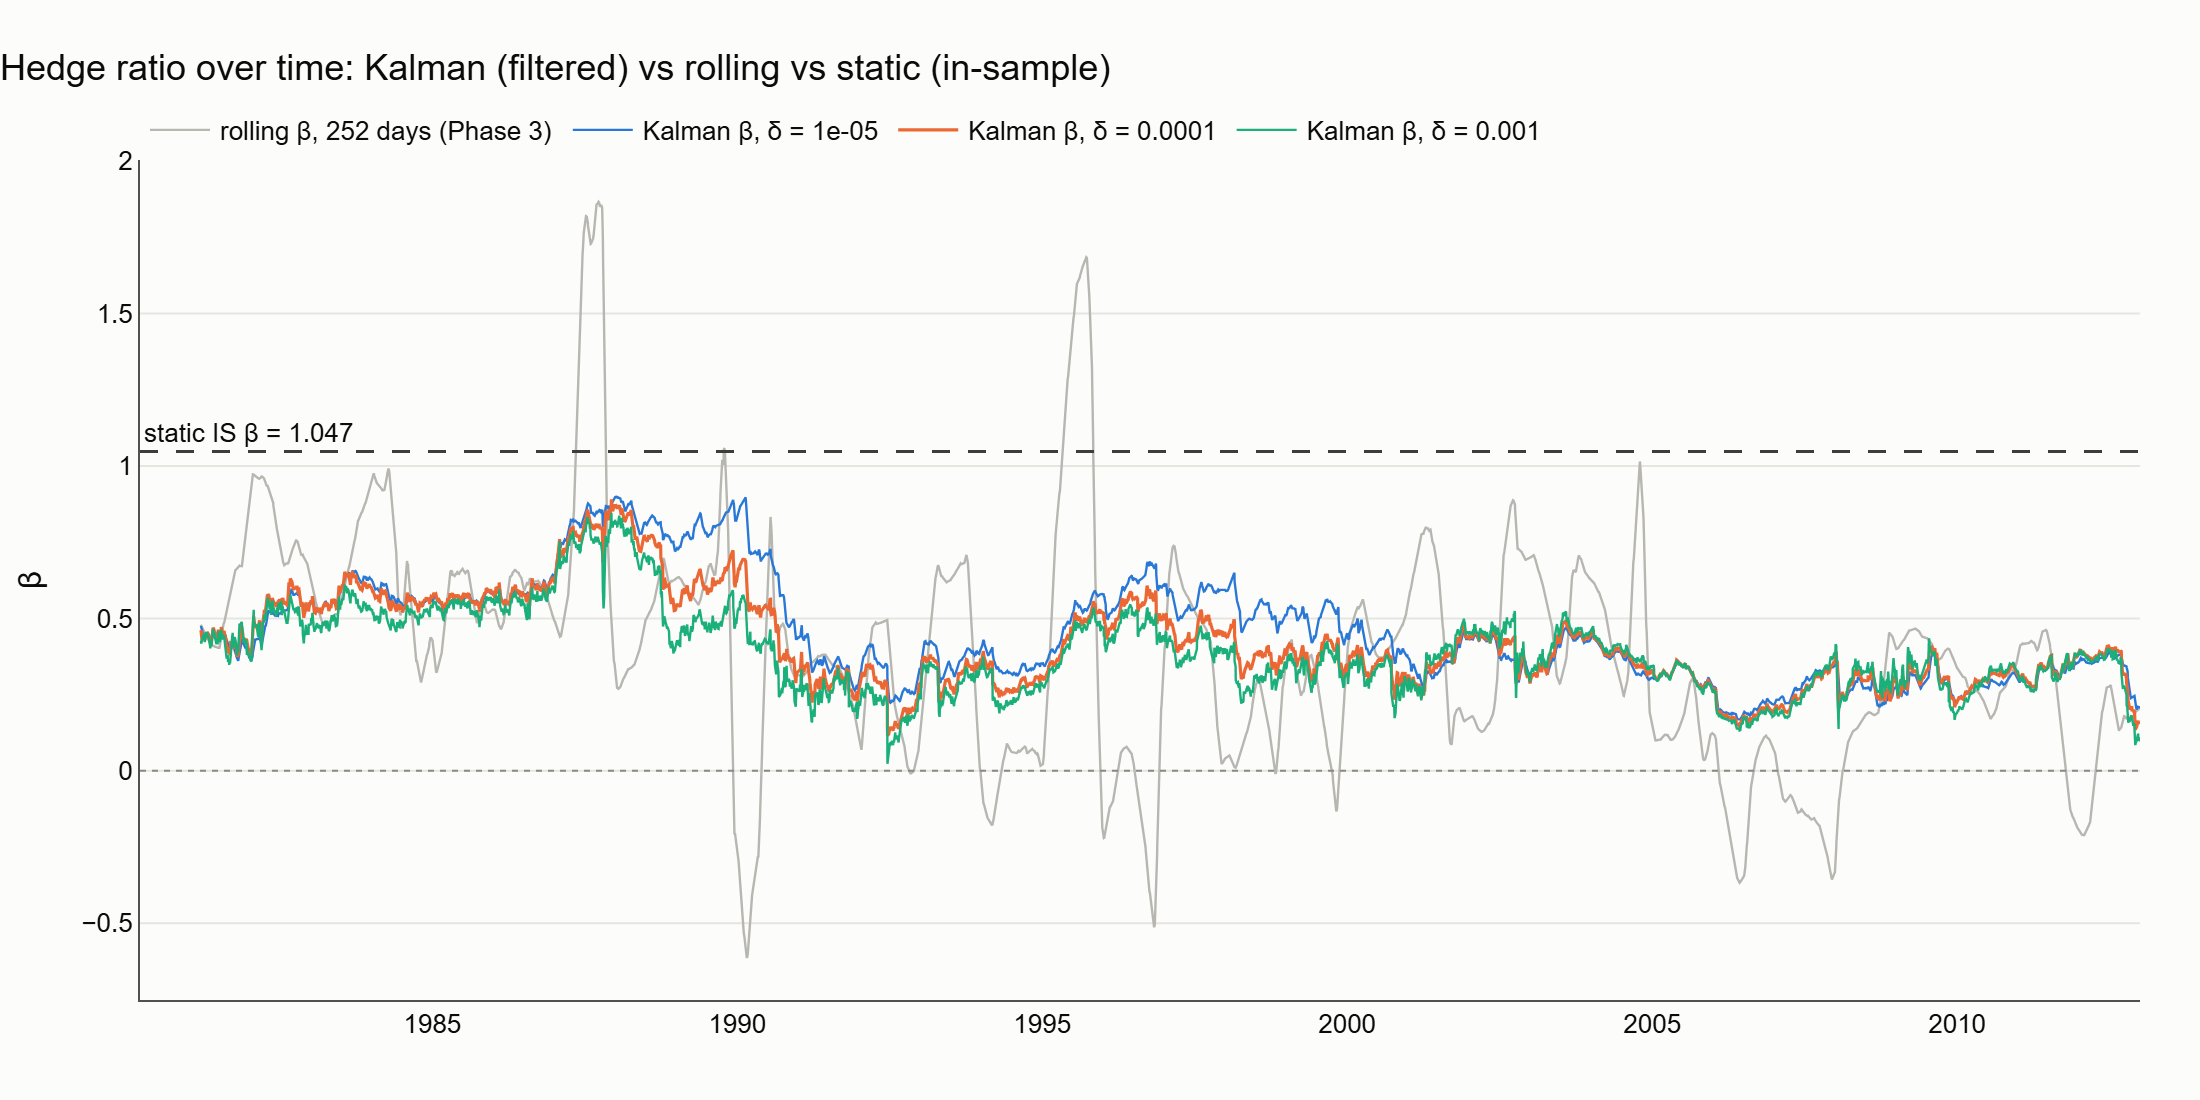

In [3]:
beta_roll = rolling_beta(prices_is, end=SPLIT_DATE)
fig = go.Figure()
fig.add_trace(
    go.Scatter(
        x=beta_roll.index,
        y=beta_roll,
        name="rolling β, 252 days (Phase 3)",
        line={"color": "#b7b6b0", "width": 1.2},
    )
)
for d, run in kalman_is.items():
    fig.add_trace(
        go.Scatter(
            x=run.daily.index,
            y=run.daily["beta"],
            name=f"Kalman β, δ = {d:g}",
            line={"color": DELTA_COLORS[d], "width": 1.6 if d == KALMAN_DELTA_MAIN else 1.2},
        )
    )
fig.add_hline(
    y=fit.beta,
    line={"color": STATIC_COLOR, "width": 1.5, "dash": "dash"},
    annotation_text=f"static IS β = {fit.beta:.3f}",
    annotation_position="top left",
)
fig.add_hline(y=0, line={"color": "#8a8984", "width": 1, "dash": "dot"})
apply_style(fig, "Hedge ratio over time: Kalman (filtered) vs rolling vs static (in-sample)")
fig.update_xaxes(range=[prices_is.index[0], prices_is.index[-1]])
fig.update_yaxes(title_text="β")
_, png = save_figure(fig, "06a_kalman_beta_is")
display(Image(filename=png))

### IS net equity: Kalman δ = 1e-4 vs static, on the same window

INFO pairs.plotting: Saved figure 06b_equity_kalman_vs_static_is (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


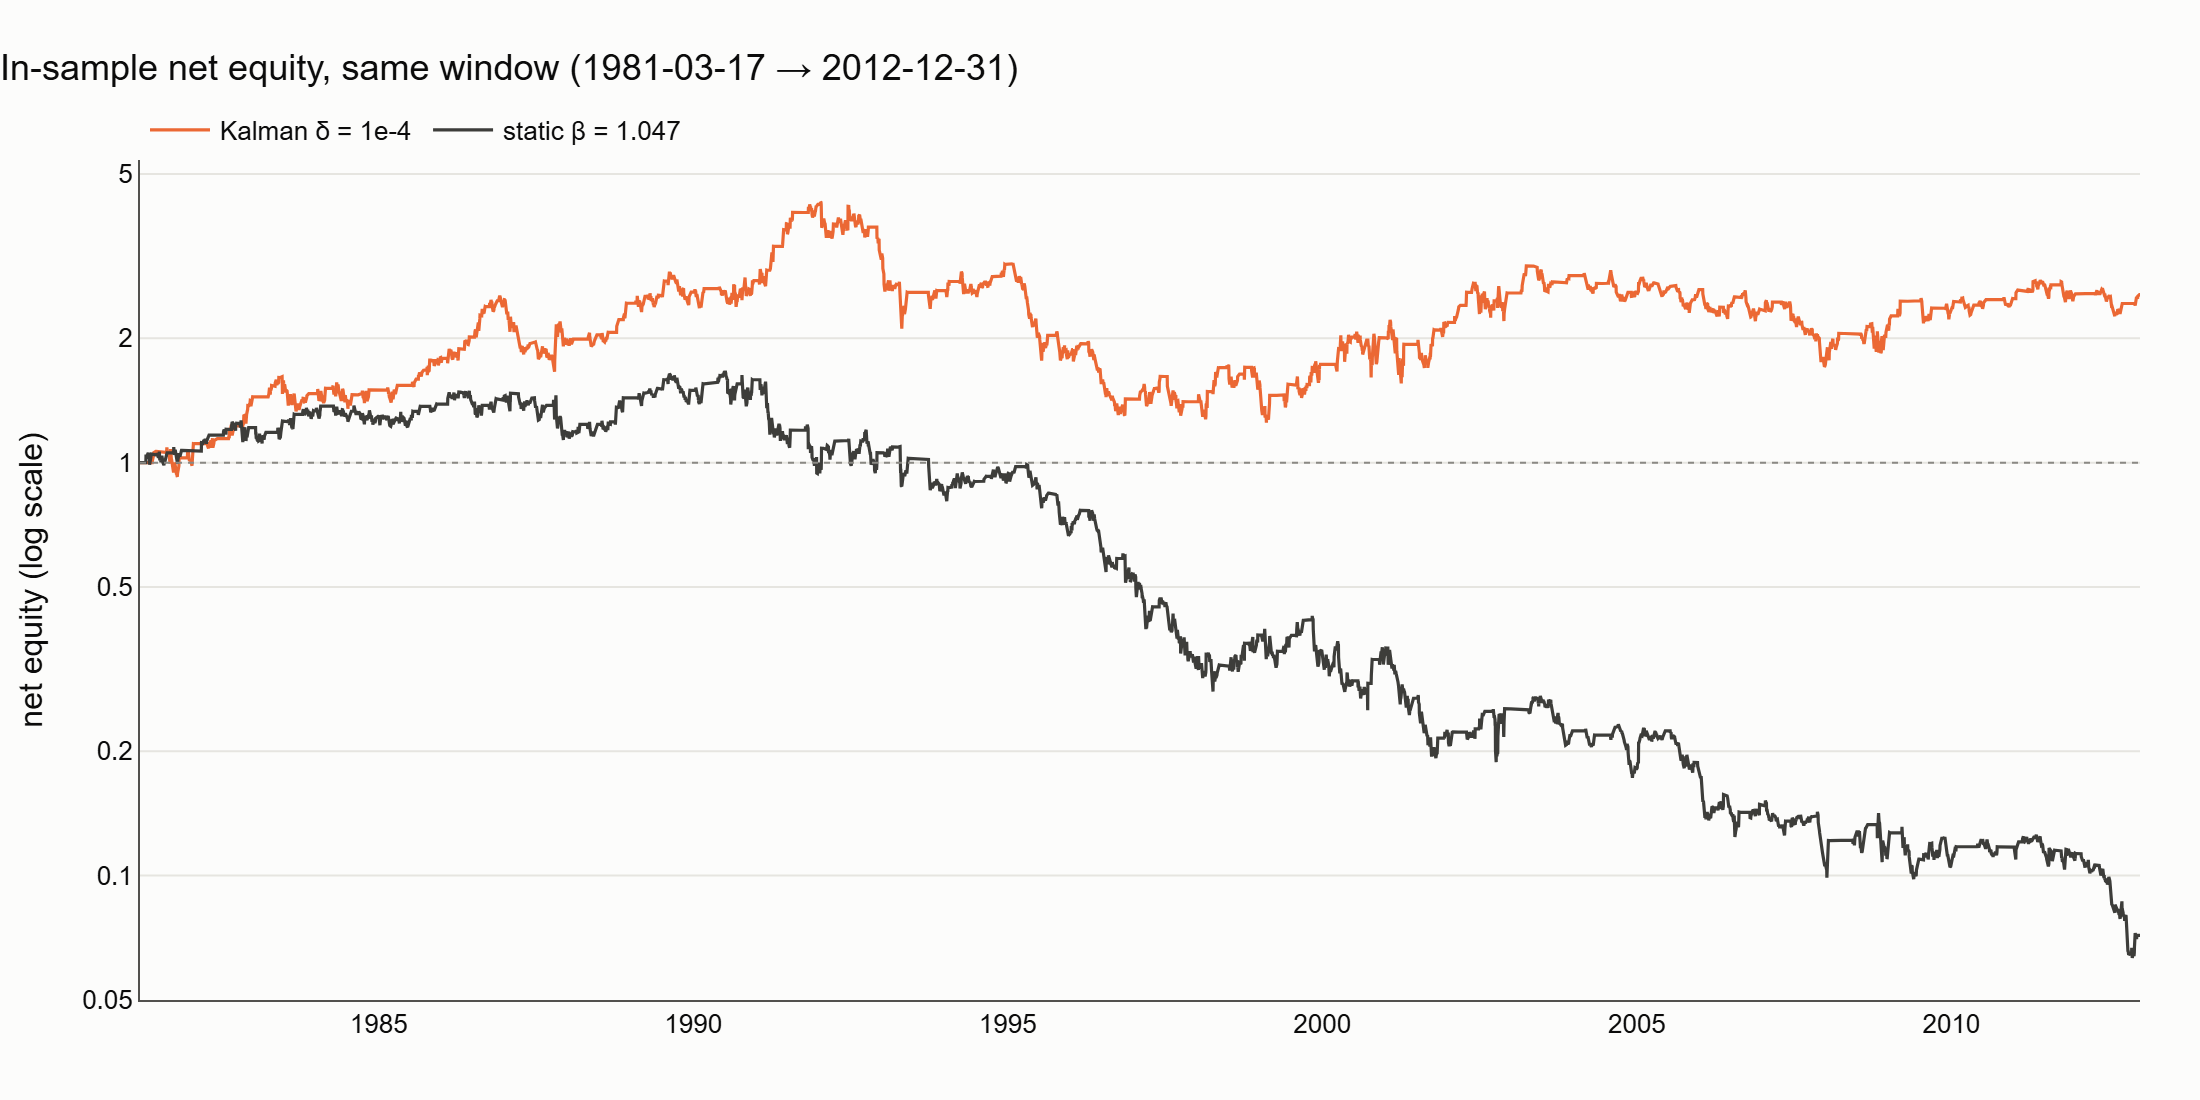

In [4]:
k_main_is = kalman_is[KALMAN_DELTA_MAIN].daily
static_cut = static_is.daily[static_is.daily.index >= pd.Timestamp(k_from)]
assert k_main_is.index.equals(static_cut.index)

fig = go.Figure()
for name, daily, color in (
    ("Kalman δ = 1e-4", k_main_is, DELTA_COLORS[KALMAN_DELTA_MAIN]),
    ("static β = 1.047", static_cut, STATIC_COLOR),
):
    eq = (1 + daily["net_ret"]).cumprod()
    fig.add_trace(go.Scatter(x=eq.index, y=eq, name=name, line={"color": color, "width": 1.6}))
fig.add_hline(y=1, line={"color": "#8a8984", "width": 1, "dash": "dot"})
apply_style(fig, "In-sample net equity, same window (1981-03-17 → 2012-12-31)")
fig.update_yaxes(
    type="log", tickvals=[0.05, 0.1, 0.2, 0.5, 1, 2, 5], title_text="net equity (log scale)"
)
_, png = save_figure(fig, "06b_equity_kalman_vs_static_is")
display(Image(filename=png))

## 2. OOS access #2: single out-of-sample run of the Kalman strategy (δ = 1e-4)

Logged in `EXPERIMENTS.md` at 16:12 CEST before computing. The filter runs from 1980 without interruption (it continues from its IS state; asserted below). The static OOS reference is OOS access #1, recomputed with the same code (identical by construction, asserted).

In [5]:
prices = load_pair(end=OOS_END)
assert prices.index.max() == pd.Timestamp("2026-10-09")

# The full-data filter must coincide with the IS filter on the IS days (no re-initialization).
state_full = kalman_filter(prices, end=OOS_END, delta=KALMAN_DELTA_MAIN)
state_is = kalman_filter(prices_is, end=SPLIT_DATE, delta=KALMAN_DELTA_MAIN)
pd.testing.assert_frame_equal(state_full.loc[state_is.index], state_is)

# OOS access #2 — the single OOS run.
kalman_oos = run_kalman_strategy(
    prices, delta=KALMAN_DELTA_MAIN, end=OOS_END, trade_from=SPLIT_DATE
)
assert kalman_oos.daily["position"].iloc[0] == 0
assert kalman_oos.daily.index[0] >= pd.Timestamp(SPLIT_DATE)

# Static OOS reference (OOS access #1, same code and parameters).
static_oos = run_strategy(
    prices, fit.beta, entry=2.0, lookback=60, end=OOS_END, trade_from=SPLIT_DATE
)
static_oos_summary = performance_summary(static_oos.daily, static_oos.trades)
assert (
    round(static_oos_summary["sharpe_net"], 2) == -0.18
    and int(static_oos_summary["n_trades"]) == 51
)
assert kalman_oos.daily.index.equals(static_oos.daily.index)

INFO pairs.data: Loaded INTC/AMD: 11737 common days, 1980-03-17 -> 2026-10-09 (end=2026-10-10, exclusive)


INFO pairs.kalman: Kalman delta=0.0001: 54 trades, 2013-01-02..2026-10-09


INFO pairs.backtest: log e=2.0 L=60 lag=1: 51 trades, 2013-01-02..2026-10-09


### OOS net equity: Kalman δ = 1e-4 vs static

INFO pairs.plotting: Saved figure 06c_equity_kalman_vs_static_oos (.html, .png) in C:\Users\cloti\Documents\Projects\challenge_BSQ\reports\figures


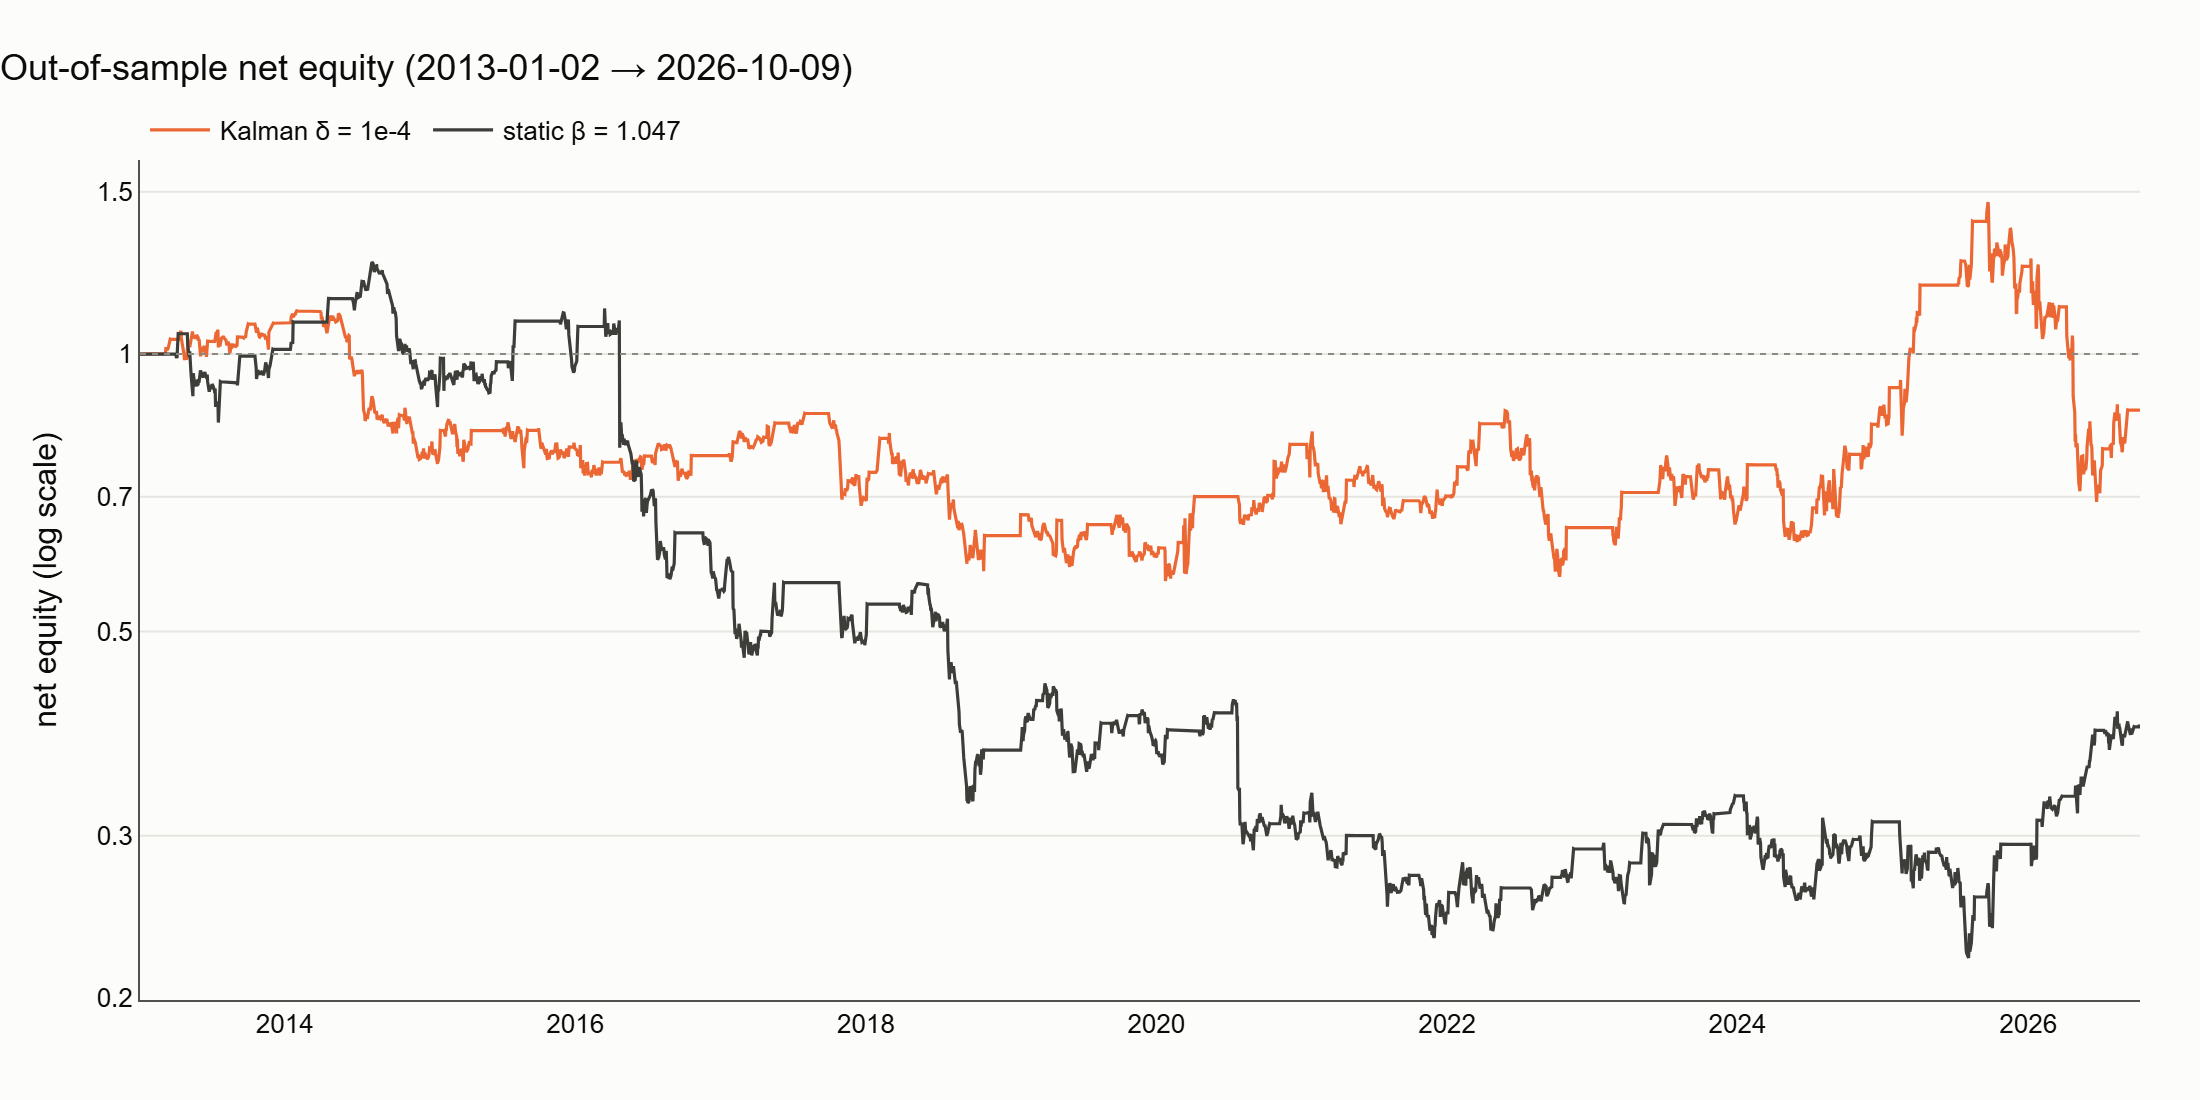

In [6]:
fig = go.Figure()
for name, daily, color in (
    ("Kalman δ = 1e-4", kalman_oos.daily, DELTA_COLORS[KALMAN_DELTA_MAIN]),
    ("static β = 1.047", static_oos.daily, STATIC_COLOR),
):
    eq = (1 + daily["net_ret"]).cumprod()
    fig.add_trace(go.Scatter(x=eq.index, y=eq, name=name, line={"color": color, "width": 1.6}))
fig.add_hline(y=1, line={"color": "#8a8984", "width": 1, "dash": "dot"})
apply_style(fig, "Out-of-sample net equity (2013-01-02 → 2026-10-09)")
fig.update_yaxes(
    type="log",
    tickvals=[0.1, 0.2, 0.3, 0.5, 0.7, 1, 1.5, 2, 3, 5],
    title_text="net equity (log scale)",
)
_, png = save_figure(fig, "06c_equity_kalman_vs_static_oos")
display(Image(filename=png))

## 3. All metrics

IS columns on the Kalman window (1981-03-17 → 2012-12-31); OOS columns on 2013-01-02 → 2026-10-09. Returns, volatility, drawdowns, win rate and exposure in %.

In [7]:
table = pd.DataFrame(
    {
        **{
            f"IS Kalman δ={d:g}": performance_summary(r.daily, r.trades)
            for d, r in kalman_is.items()
        },
        "IS static (same window)": static_is_summary,
        "OOS Kalman δ=1e-4": performance_summary(kalman_oos.daily, kalman_oos.trades),
        "OOS static": static_oos_summary,
    }
)
pct_prefixes = ("ann_return", "ann_vol", "max_dd")
pct_rows = [r for r in table.index if r.startswith(pct_prefixes)] + ["win_rate_net", "exposure"]
table.loc[pct_rows] = table.loc[pct_rows] * 100
table = table.rename(index={r: f"{r} %" for r in pct_rows})
table.round(2)

,IS Kalman δ=1e-05,IS Kalman δ=0.0001,IS Kalman δ=0.001,IS static (same window),OOS Kalman δ=1e-4,OOS static
ann_return_gross %,3.05,3.39,4.55,-7.62,-0.62,-6.22
ann_vol_gross %,20.12,20.35,20.27,22.14,23.15,22.80
sharpe_gross,0.25,0.27,0.32,-0.25,0.09,-0.16
max_dd_gross %,-67.77,-70.11,-69.22,-95.93,-52.63,-81.80
ann_return_net %,2.65,2.99,4.13,-7.95,-1.01,-6.56
ann_vol_net %,20.12,20.35,20.27,22.14,23.15,22.80
sharpe_net,0.23,0.25,0.30,-0.26,0.07,-0.18
max_dd_net %,-68.28,-70.79,-69.71,-96.21,-52.73,-82.44
n_trades,124.00,125.00,128.00,113.00,54.00,51.00
win_rate_net %,67.74,68.00,70.31,53.98,64.81,60.78


In [8]:
# Descriptive: the filtered beta in the OOS period.
b_oos = kalman_oos.daily["beta"]
pd.Series(
    {
        "min": b_oos.min(),
        "median": b_oos.median(),
        "max": b_oos.max(),
        "last (2026-10-09)": b_oos.iloc[-1],
    },
    name="Kalman β (δ = 1e-4), OOS",
).round(3).to_frame()

,"Kalman β (δ = 1e-4), OOS"
min,0.052
median,0.186
max,0.505
last (2026-10-09),0.475


### How precise is an OOS Sharpe over 13.8 years?

Approximate standard error of an annualized Sharpe ratio under iid returns (Lo, 2002): `SE ≈ sqrt((1 + SR²/2) / years)`. Descriptive only (autocorrelation makes it optimistic); not a pre-registered test.

In [9]:
years = len(kalman_oos.daily) / 252
rows = {}
for name, s in (
    ("OOS Kalman δ=1e-4", table.loc["sharpe_net", "OOS Kalman δ=1e-4"]),
    ("OOS static", table.loc["sharpe_net", "OOS static"]),
):
    sr = float(s)
    se = ((1 + sr**2 / 2) / years) ** 0.5
    rows[name] = {
        "sharpe_net": sr,
        "approx SE": se,
        "approx 95% low": sr - 1.96 * se,
        "approx 95% high": sr + 1.96 * se,
    }
print(f"OOS length: {years:.1f} years")
pd.DataFrame(rows).T.round(2)

OOS length: 13.7 years


,sharpe_net,approx SE,approx 95% low,approx 95% high
OOS Kalman δ=1e-4,0.07,0.27,-0.46,0.60
OOS static,-0.18,0.27,-0.71,0.35


## Observations

- **β:** the filtered β moves smoothly between about 0.1 and 0.9 in-sample (median ≈ 0.38 for δ = 1e-4), tracking the level of the Phase 3 rolling β without its wild swings, and far below the static 1.047. In the OOS it drifts lower still (median 0.19, range 0.05–0.51).
- **In-sample, the Kalman clearly beats the static hedge:** net Sharpe 0.23 / 0.25 / 0.30 for δ = 1e-5 / 1e-4 / 1e-3 versus −0.26 for the static strategy on the same window; annualized net return +2.7% to +4.1% versus −8.0%. The IS result **does not depend much on δ** across two orders of magnitude. But most of the IS gain is made before 1992; from its early-1990s peak the equity ends lower, and the max drawdown is still ≈ −70%.
- **Out-of-sample (single run, δ = 1e-4): better than static, but not a profitable strategy.** Net Sharpe +0.07 vs −0.18 for the static strategy; annualized net return −1.0% vs −6.6% (the Sharpe is slightly positive while the compounded return is negative: volatility drag); max drawdown −53% vs −82%. The approximate 95% interval of the OOS Sharpe is −0.46 to +0.60: indistinguishable from zero. Much of the late OOS gain (2024–2025) was given back in 2026.
- **IS → OOS decay:** net Sharpe falls from 0.25 to 0.07. Part of the IS advantage was specific to the IS period, and the extension itself was motivated by an IS analysis (Phase 3), so some optimism in the IS numbers is expected.
- **Known property of the design:** the z-score uses β_t already updated with day t's prices, so the filter partly absorbs day t's deviation; this may dampen the signal relative to a prediction-error z-score (Chan's formulation). It was fixed in advance and not changed.
- **Conclusion:** hedging with the local β removes most of the static strategy's losses — consistent with the Phase 3 diagnosis that the static spread was mostly an AMD position — but it does not reveal a mean-reverting relationship that can be traded profitably out-of-sample.